## Manage ArcGIS Enterprise Server and Portal

Automate monitoring of your portal and server in ArcGIS Enterprise

> NOTE: You need administrator privileges for this organization to run this notebook.

#### Import necessary libraries and connect to GIS

In [1]:
from arcgis.gis import GIS
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import numpy as np
import datetime

gis = GIS("home")

You are logged on as mmajumdar with an administrator role, proceed with caution.


#### Define variables

In [2]:
number_of_days = 30

#### Compute timeframe based on `number_of_days` picked

In [3]:
# most recent time to query
start_time = datetime.datetime.now()
# oldest time to query upto
end_time = start_time - datetime.timedelta(days=number_of_days)

now_readable = start_time.strftime('%d-%m-%y')

### Portal logs

In [4]:
portal_logs = gis.admin.logs
portal_results = portal_logs.query(start_time = start_time, end_time = end_time)

#### Chart portal logs based on distribution of `WARNING` v/s `SEVERE` log message

<AxesSubplot: xlabel='type'>

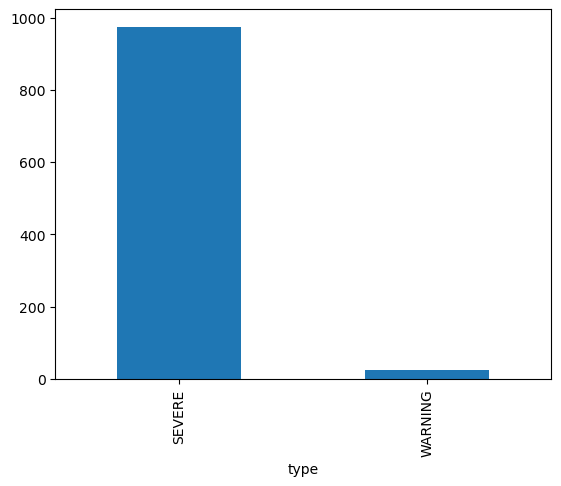

In [5]:
%matplotlib inline
portal_logs_df = pd.DataFrame(portal_results['logMessages'])
portal_logs_df.type.value_counts().plot.bar()

In [6]:
portal_logs_df.head()

,type,message,time,source,machine,user,code,elapsed,process,thread,methodName,requestID
0,SEVERE,Invalid SSL certificate found. PKIX path buil...,1753841563533,Sharing,10.0.0.156,,204084,0.0,3451,1,,
1,SEVERE,Invalid SSL certificate found. PKIX path buil...,1753841563529,Sharing,10.0.0.156,,204084,0.0,3451,1,,
2,SEVERE,Invalid SSL certificate found. PKIX path buil...,1753841563523,Sharing,10.0.0.156,,204084,0.0,3451,1,,
3,SEVERE,Invalid SSL certificate found. PKIX path buil...,1753839763349,Sharing,10.0.0.156,,204084,0.0,3451,1,,
4,SEVERE,Invalid SSL certificate found. PKIX path buil...,1753839763344,Sharing,10.0.0.156,,204084,0.0,3451,1,,


#### Save this table as a CSV file in your workspace

In [ ]:
file_path = '/arcgis/home/portal_logs_' + now_readable
portal_logs_df.to_csv(file_path)

### Server logs

#### Fetch federated servers

In [8]:
servers = gis.admin.servers.list()
servers

[< Server @ https://pythonapitestnb.dev.geocloud.com/rasteranalytics/admin >,
 < Server @ https://pythonapitestnb.dev.geocloud.com/server/admin >,
 < Server @ https://pythonapitestnb.dev.geocloud.com/workflowmanager/admin >,
 < MissionServer @ https://pythonapitestnb.dev.geocloud.com/missionserver/admin >,
 < NotebookServer @ https://pythonapitestnb.dev.geocloud.com/notebookserver/admin >,
 < Server @ https://pythonapitestnb.dev.geocloud.com/knowledge/admin >]

#### Query server logs for a particular server

For any server of choice, you can query its logs and export it as a CSV file using the index of the server in the list above.

In [ ]:
server = servers[1]

In [9]:
server_logs = server.logs
server_results = server_logs.query(start_time = start_time, end_time = end_time)['logMessages']

In [10]:
server_logs_df = pd.DataFrame(server_results)
server_logs_df.head()

,type,message,time,source,machine,user,code,elapsed,process,thread,methodName,requestID
0,WARNING,"Type of Layer: 'Lots' is 'Group Layer', which ...",1753833684787,SimpleParcelFabric.MapServer,10.0.0.156,,17001,,1449902,2168,GraphicFeatureServer::InitializeLayers,1fc41ee2-ded5-4ea4-8287-81a70d5410c9
1,WARNING,"Type of Layer: 'Parcels' is 'Group Layer', whi...",1753833683012,SimpleParcelFabric.MapServer,10.0.0.156,,17001,,1449902,2168,GraphicFeatureServer::InitializeLayers,1fc41ee2-ded5-4ea4-8287-81a70d5410c9
2,SEVERE,Initialization of Layer: AdjustmentLines failed.,1753833682131,SimpleParcelFabric.MapServer,10.0.0.156,,17000,,1449902,2168,GraphicFeatureServer::InitializeLayers,1fc41ee2-ded5-4ea4-8287-81a70d5410c9
3,SEVERE,Error during renderer specific initialiation f...,1753833682130,SimpleParcelFabric.MapServer,10.0.0.156,,17135,,1449902,2168,GraphicFeatureLayer::InitByLayer,1fc41ee2-ded5-4ea4-8287-81a70d5410c9
4,WARNING,"Type of Layer: 'Analysis' is 'Group Layer', wh...",1753833680357,SimpleParcelFabric.MapServer,10.0.0.156,,17001,,1449902,2168,GraphicFeatureServer::InitializeLayers,1fc41ee2-ded5-4ea4-8287-81a70d5410c9


#### Save this table as a CSV file in your workspace

In [ ]:
file_path = '/arcgis/home/server_logs_' + now_readable
server_logs_df.to_csv(file_path)

### Built in reports for the particular server

#### Use built-in reports to query maximum response times for the last 7 days

In [11]:
# Fetch usage reports for the server
usage = server.usage
reports = usage.list()
data_usage = reports[0].query()

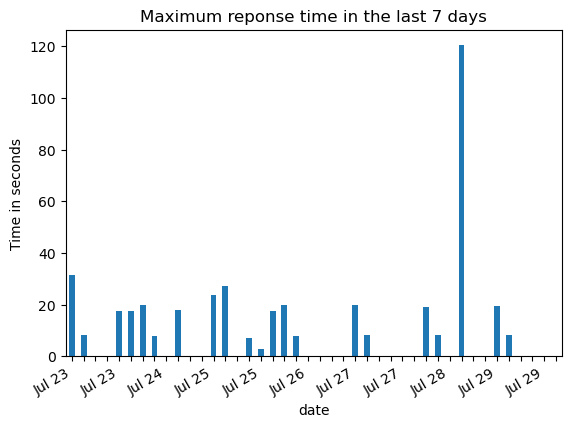

In [12]:
#store reponse times in Y axis
data_y = data_usage['report']['report-data'][0][0]['data']

#convert dates to readable dates and store in X axis
data_x = [pd.to_datetime(datetime.datetime.fromtimestamp(d//1000)) \
          for d in data_usage['report']['time-slices']]

df = pd.DataFrame(list(zip(data_x, data_y)), columns=["date", "count"])
q = df['count'].isnull() # change NaN values to 0
df.loc[q, 'count'] = 0
df.index = df['date']
df['count'] = df['count'] 

ax = df['count'].plot(kind='bar', x=df['date'])
ticklabels = ['']*len(df.index)
ticklabels[::4] = [item.strftime('%b %d') for item in df.index[::4]]
ax.xaxis.set_major_formatter(ticker.FixedFormatter(ticklabels))
ax.set_title('Maximum reponse time in the last 7 days')
ax.set_ylabel('Time in seconds')
plt.gcf().autofmt_xdate()
plt.show()

### License Management

#### Access license entitlements for each user in the organization

In [13]:
licenses = gis.admin.license.all()
licenses

[<ArcGIS Location Sharing License @ https://pythonapitestnb.dev.geocloud.com/portal/sharing/rest/ >,
 <ArcGIS Navigator License @ https://pythonapitestnb.dev.geocloud.com/portal/sharing/rest/ >,
 <ArcGIS Advanced Editing License @ https://pythonapitestnb.dev.geocloud.com/portal/sharing/rest/ >,
 <Runtime StreetMap Premium Middle East and Africa License @ https://pythonapitestnb.dev.geocloud.com/portal/sharing/rest/ >,
 <ArcGIS Business Analyst Web and Mobile Apps License @ https://pythonapitestnb.dev.geocloud.com/portal/sharing/rest/ >,
 <Runtime StreetMap Premium Latin America License @ https://pythonapitestnb.dev.geocloud.com/portal/sharing/rest/ >,
 <Runtime StreetMap Premium North America License @ https://pythonapitestnb.dev.geocloud.com/portal/sharing/rest/ >,
 <ArcGIS Pro License @ https://pythonapitestnb.dev.geocloud.com/portal/sharing/rest/ >,
 <ArcGIS CityEngine License @ https://pythonapitestnb.dev.geocloud.com/portal/sharing/rest/ >,
 <Runtime StreetMap Premium Europe Licen

In [14]:
license_info = []
for lic in licenses:
    try:
        stats = lic.all()
        for s in stats:
            s['entitlements'] = ",".join(s['entitlements'])
        license_info.extend(stats)
    except:
        ...

In [15]:
license_df = pd.DataFrame(license_info)
license_df.head()

,username,lastLogin,disconnected,entitlements
0,arcgis_python,-1,False,"workflowMgrN,networkAnalystN"
1,arcgispyapibot,-1,False,"workflowMgrN,networkAnalystN"
2,uc2025_enterprise,-1,False,desktopAdvN


#### Save this table as a CSV file in your workspace

In [ ]:
file_path = '/arcgis/home/license_entitlements_' + now_readable
license_df.to_csv(file_path)